# Efek Campaign Voucher: Difference-in-Differences — Observasional

Retailer yang memilih siapa yang dikirimi campaign bukan undian acak — jadi tidak ada angka di notebook ini yang berdiri sebagai klaim kausal. Semua estimasi berlabel **`observasional — di bawah asumsi unconfoundedness`**, dan pekerjaan utamanya justru menguji seberapa jauh asumsi itu dapat dipertahankan: parallel pre-trend, overlap propensity, dan covariate balance.

Kisah singkatnya: dari 30 campaign, 20 layak diperkirakan efeknya; setelah tiga ujian diagnostik, hanya **4 yang lolos semuanya** — dua backbone (13 dan 18) menunjukkan lift spend mingguan yang signifikan (+11,4% dan +17,2%), satu borderline (8), satu kecil tapi bersih (30). Sisanya tetap dilaporkan dengan flag dan alasan, tidak dibuang diam-diam.

## 0. Setup

In [1]:
import sys
from pathlib import Path

REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.did import build_campaign_results
from src.features import PROCESSED_DIR, save_parquet

panel = pd.read_parquet(PROCESSED_DIR / "hh_week.parquet")
timeline = pd.read_parquet(PROCESSED_DIR / "campaign_timeline.parquet")
hh_campaign = pd.read_parquet(PROCESSED_DIR / "hh_campaign.parquet")
results, events = build_campaign_results(timeline, hh_campaign, panel)
save_parquet(results, PROCESSED_DIR / "campaign_did_results.parquet")
save_parquet(events, PROCESSED_DIR / "campaign_event_study.parquet")
est = results[results["estimated"]].copy()
print(f"{len(results)} campaign | {len(est)} diperkirakan | {len(events):,} baris event study")

30 campaign | 20 diperkirakan | 574 baris event study


## 1. Siapa dibandingkan dengan siapa

Untuk tiap campaign, treated dibandingkan dengan household yang tidak ditarget campaign itu **dan** tidak sedang menerima campaign lain yang window-nya beririsan — tanpa itu, kontrol tercemar dan estimasi tertarik ke nol. Baseline spend diambil dari 8 minggu sebelum campaign; efek diukur pada rata-rata spend mingguan selama window (normalisasi untuk panjang window 5–14 minggu). Pembobotan IPW membuat kontrol menyerupai treated pada lima fitur pre-window: spend, frekuensi aktif, ketergantungan promo, ragam kategori, recency.

In [2]:
cols = ["campaign_id", "type", "n_weeks_window", "n_treated_analysis", "n_control_analysis", "trim_share"]
view = est[cols].copy().round(3)
view["n_control_analysis"] = view["n_control_analysis"].astype(int)
view  # diurut sesuai timeline

,campaign_id,type,n_weeks_window,n_treated_analysis,n_control_analysis,trim_share
4,5,B,5,148.0,721,0.608
6,7,B,5,177.0,471,0.590
7,8,A,7,1013.0,1117,0.125
8,9,B,5,166.0,592,0.508
9,10,B,5,100.0,537,0.693
10,11,B,7,193.0,430,0.608
11,12,B,5,141.0,406,0.646
12,13,A,7,999.0,1189,0.107
13,14,C,10,172.0,443,0.552
15,16,B,5,164.0,418,0.611


## 2. Overlap dan balance — di mana asumsi bertahan

Kontrol yang jauh berbeda dari treated tidak punya pasangan pembanding yang jujur; trim propensity membuangnya, dengan harga menyusutnya sampel. Untuk backbone (treated > 1.000) overlap sehat: hanya 10–13% yang ter-trim dan **SMD maksimum setelah pembobotan turun di bawah 0,1**. Untuk campaign menengah (treated 100–350) kenyataannya berat: lebih dari separuh sampel ter-trim dan residual imbalance tetap di atas ambang — 16 dari 20 campaign gagal balance dan **flag-nya dipertahankan**. Pemeriksaan sensitivitas (trim hanya sisi treated, atau tanpa trim) tidak memperbaikinya — imbalance itu nyata, bukan artefak aturan trim.

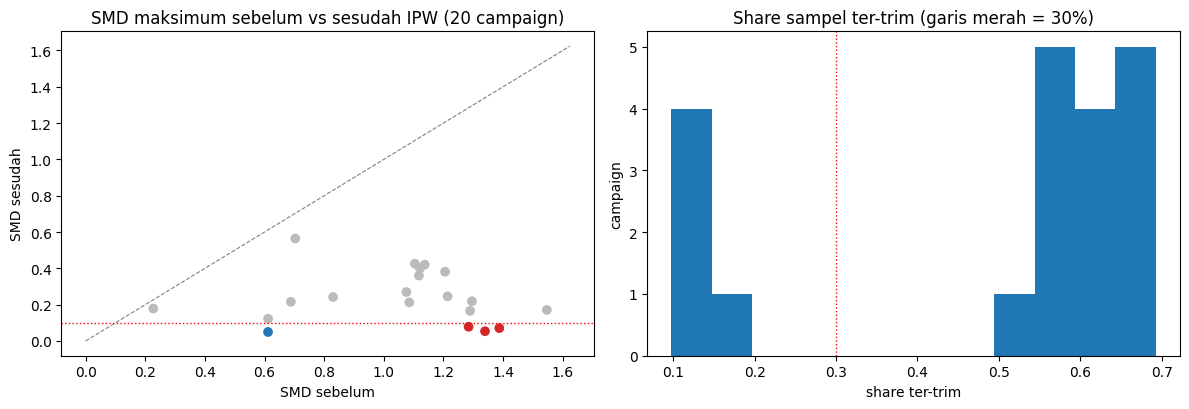

 campaign_id  smd_max_before  smd_max_after  trim_share
           8           1.284          0.078       0.125
          13           1.339          0.054       0.107
          18           1.387          0.071       0.098


In [3]:
bb_mask = est["campaign_id"].isin((8, 13, 18))
colors = np.where(bb_mask, "#d62728", np.where(est["reliability_flag"].str.startswith("layak"), "#1f77b4", "#bbbbbb"))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].scatter(est["smd_max_before"], est["smd_max_after"], c=colors)
lim = max(est["smd_max_before"].max(), est["smd_max_after"].max()) * 1.05
axes[0].plot([0, lim], [0, lim], color="gray", lw=0.8, ls="--")
axes[0].axhline(0.1, color="red", ls=":", lw=1)
axes[0].set(title="SMD maksimum sebelum vs sesudah IPW (20 campaign)", xlabel="SMD sebelum", ylabel="SMD sesudah")
axes[1].hist(est["trim_share"], bins=12, color="#1f77b4")
axes[1].axvline(0.3, color="red", ls=":", lw=1)
axes[1].set(title="Share sampel ter-trim (garis merah = 30%)", xlabel="share ter-trim", ylabel="campaign")
plt.tight_layout()
plt.show()
print(est.loc[bb_mask, ["campaign_id", "smd_max_before", "smd_max_after", "trim_share"]].round(3).to_string(index=False))

## 3. Event study — tiga campaign backbone

Spend mingguan berbobot treated vs kontrol di sekitar awal campaign (minggu 0). Yang dicari: kedua garis bergerak sejajar sebelum minggu 0, lalu berpisah setelahnya. Placebo formal (DiD separuh awal vs separuh akhir periode pre) mengonfirmasi: ketiga backbone lolos — CI-nya memuat nol.

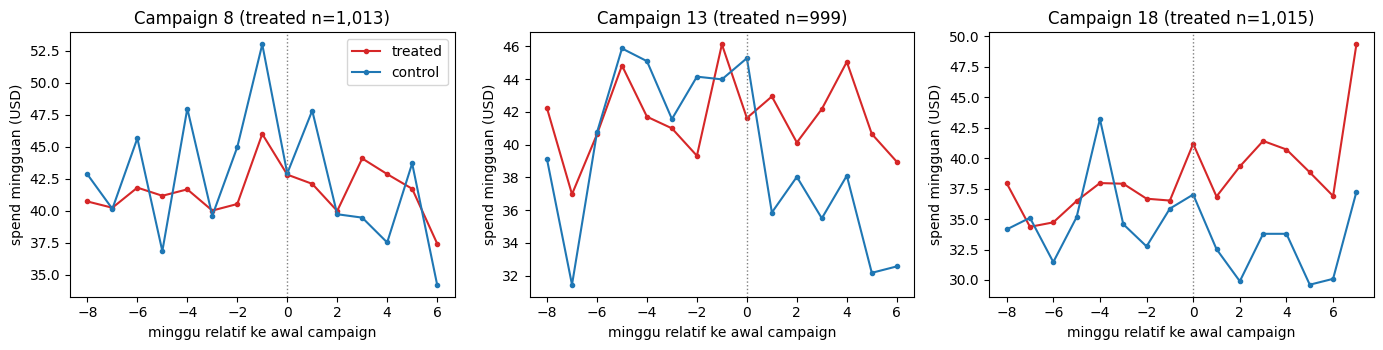

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6), sharey=False)
for ax, cid in zip(axes, (8, 13, 18)):
    sub = events[events["campaign_id"] == cid]
    for grp, color in (("treated", "#d62728"), ("control", "#1f77b4")):
        g = sub[sub["group"] == grp]
        ax.plot(g["event_week"], g["mean_weekly_spend"], "-o", ms=3, color=color, label=grp)
    ax.axvline(0, color="gray", ls=":", lw=1)
    n_t = int(est.loc[est["campaign_id"] == cid, "n_treated_analysis"].iloc[0])
    ax.set(title=f"Campaign {cid} (treated n={n_t:,})", xlabel="minggu relatif ke awal campaign", ylabel="spend mingguan (USD)")
axes[0].legend()
plt.tight_layout()
plt.show()

## 4. Hasil per campaign — lift spend mingguan

Forest plot lift % dengan 95% CI bootstrap (1.000 resample per household). Warna merah = backbone, biru = lolos semua gate, abu-abu = flag `tidak reliable` (balance/pre-trend). Dua backbone signifikan (13: **+11,4%** [4,4–18,9]; 18: **+17,2%** [9,1–24,9]), 8 borderline (+7,7% [−0,6–15,6]), 30 kecil tapi bersih (+2,8%). Angka menengah yang gagal balance tetap tampil — sebagai konteks, bukan bukti.

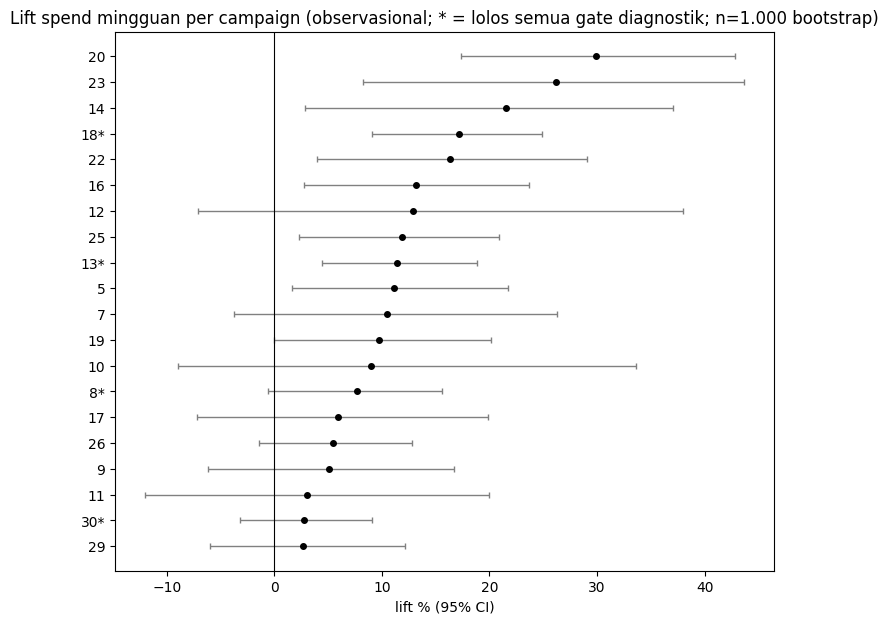

In [5]:
plot = est.sort_values("lift_pct")
colors = np.where(plot["campaign_id"].isin((8, 13, 18)), "#d62728",
         np.where(plot["reliability_flag"].str.startswith("layak"), "#1f77b4", "#bbbbbb"))
fig, ax = plt.subplots(figsize=(8.5, 7))
y = np.arange(len(plot))
ax.errorbar(plot["lift_pct"], y, xerr=[plot["lift_pct"] - plot["lift_ci_low"], plot["lift_ci_high"] - plot["lift_pct"]],
            fmt="o", ms=4, color="black", ecolor="gray", elinewidth=1, capsize=2)
for yi, c in zip(y, colors):
    ax.get_yticklabels()
ax.set_yticks(y)
ax.set_yticklabels([f"{int(c)}{'*' if f.startswith('layak') else ''}" for c, f in zip(plot["campaign_id"], plot["reliability_flag"])])
ax.axvline(0, color="black", lw=0.8)
ax.set(title="Lift spend mingguan per campaign (observasional; * = lolos semua gate diagnostik; n=1.000 bootstrap)",
       xlabel="lift % (95% CI)")
plt.show()

## 5. Ekonomi voucher — incremental spend per $1 voucher

Biaya voucher dihitung dari nilai kupon yang benar-benar diredeemasi member treated selama window (seluruh kupon — data tidak memungkinkan atribusi per-kupon ke campaign tertentu, jadi angka ini cenderung konservatif). Hasilnya straight to the point: backbone menghasilkan **$1,31–$2,16 spend incremental per $1 voucher**, tapi pada margin grocery yang realistis (15–35%) **margin incremental per $1 masih negatif** — break-even baru tercapai pada margin 46–76%. Voucher semacam ini, dinilai dari spend langsungnya saja, belum membayar dirinya sendiri.

In [6]:
eco_cols = ["campaign_id", "n_treated", "redemption_rate", "voucher_cost",
            "incremental_spend_total", "inc_spend_per_dollar",
            "margin15_per_dollar", "margin25_per_dollar", "margin35_per_dollar"]
eco = est[est["campaign_id"].isin((8, 13, 18))][eco_cols].copy()
eco["break_even_margin"] = 1 / eco["inc_spend_per_dollar"]
display(eco.round(3))
print("break-even margin = 1 / (incremental spend per $1) — margin kategori yang dibutuhkan agar voucher impas")

,campaign_id,n_treated,redemption_rate,voucher_cost,incremental_spend_total,inc_spend_per_dollar,margin15_per_dollar,margin25_per_dollar,margin35_per_dollar,break_even_margin
7,8,1076,0.147,2454.05,3218.823,1.312,-0.803,-0.672,-0.541,0.762
12,13,1077,0.182,2522.42,4751.959,1.884,-0.717,-0.529,-0.341,0.531
17,18,1133,0.189,2954.08,6381.218,2.160,-0.676,-0.460,-0.244,0.463


break-even margin = 1 / (incremental spend per $1) — margin kategori yang dibutuhkan agar voucher impas


## 6. Artefak & angka kunci

In [7]:
display(pd.DataFrame(
    [(a, f"{(PROCESSED_DIR / a).stat().st_size / 1e6:.1f} MB") for a in ("campaign_did_results.parquet", "campaign_event_study.parquet")],
    columns=["artefak (data/processed/)", "ukuran"],
))
layak = results[results["reliability_flag"].str.startswith("layak")]
print(f"lolos semua gate: {sorted(layak['campaign_id'].tolist())} | pre-trend gagal: {sorted(est.loc[~est['pre_trend_ok'], 'campaign_id'].tolist())} | balance gagal: {int((est['smd_max_after'] >= 0.1).sum())}/20")
print(results["reliability_flag"].value_counts().to_string())

,artefak (data/processed/),ukuran
0,campaign_did_results.parquet,0.0 MB
1,campaign_event_study.parquet,0.0 MB


lolos semua gate: [8, 13, 18, 30] | pre-trend gagal: [11, 12, 14] | balance gagal: 16/20
reliability_flag
tidak reliable — balance                13
tidak reliable                           9
layak — utama (observasional)            3
tidak reliable — pre-trend & balance     3
excluded                                 1
layak (observasional)                    1


## Catatan kualitas & batasan

- **Semua estimasi bersifat observasional** — valid di bawah asumsi unconfoundedness; propensity, balance, dan placebo mengurangi risikonya, bukan menghapus.
- Hanya 4 dari 20 campaign lolos semua gate diagnostik (8, 13, 18, 30). Enam belas campaign menengah gagal covariate balance (SMD ≥ 0,1) — bukan artefak aturan trim (sensitivitas trim alternatif tidak memperbaiki), melainkan seleksi treated yang sangat berat pada spender besar; estimasinya dilaporkan dengan flag, bukan dibuang.
- Tiga campaign gagal placebo pre-trend (11, 12, 14) — flagged.
- Trim propensity membuang median 58% sampel di campaign menengah (prevalensi treated rendah); estimasi pada populasi ter-trim, bukan seluruh member.
- Biaya voucher menghitung **seluruh kupon** yang diredeemasi member treated selama window, bukan hanya kupon campaign itu — konservatif; atribusi per-kupon tidak dimungkinkan data.
- Break-even margin backbone 46–76% — di atas margin grocery umum; kesimpulan ekonomi menunggu simulasi ROI penuh (margin sebagai parameter, bukan angka tunggal).
- Semua nominal USD historis; CI dari bootstrap 1.000 resample per household.